In [1]:
import numpy as np, pandas as pd, joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

train = pd.read_csv("../data/UNSW_NB15_training-set.csv")
test = pd.read_csv("../data/UNSW_NB15_testing-set.csv")

DROP = ["id", "attack_cat", "label"]
CAT = ["proto", "service", "state"]
NUM = [c for c in train.columns if c not in DROP + CAT]

X, y = train.drop(columns=DROP), train["label"]
X_test, y_test = test.drop(columns=DROP), test["label"]

In [2]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [3]:
def make_pre(scale):
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
        ("num", num, NUM),
    ])

In [4]:
def metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    prec = tp / (tp + fp) if tp + fp else 0
    rec = tp / (tp + fn)
    return dict(thr=thr, acc=(tp + tn) / len(y_true), precision=prec,
                recall=rec, f1=2 * prec * rec / (prec + rec + 1e-12),
                fpr=fp / (fp + tn), fnr=fn / (fn + tp), tn=tn, fp=fp, fn=fn, tp=tp)

In [5]:
models = {
    "RandomForest": Pipeline([("pre", make_pre(False)),
        ("m", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42))]),
    "HistGB": Pipeline([("pre", make_pre(False)),
        ("m", HistGradientBoostingClassifier(random_state=42))]),
    "LogReg": Pipeline([("pre", make_pre(True)),
        ("m", LogisticRegression(max_iter=1000))]),
}
rows = []
for name, pipe in models.items():
    pipe.fit(X_tr, y_tr)
    p = pipe.predict_proba(X_val)[:, 1]
    rows.append({"model": name, **metrics(y_val, p)})
pd.DataFrame(rows)[["model", "acc", "precision", "recall", "f1", "fpr", "fnr"]]

,model,acc,precision,recall,f1,fpr,fnr
0,RandomForest,0.960221,0.963764,0.978340,0.970997,0.078393,0.021660
1,HistGB,0.955801,0.959863,0.975868,0.967800,0.086964,0.024132
2,LogReg,0.936268,0.923499,0.988227,0.954767,0.174464,0.011773


In [6]:
best = "HistGB"   # change this to whichever model won in Cell 5
p_val = models[best].predict_proba(X_val)[:, 1]
sweep = pd.DataFrame([metrics(y_val, p_val, t) for t in np.arange(0.3, 0.91, 0.05)])
sweep[["thr", "precision", "recall", "f1", "fpr", "fnr"]].round(3)

,thr,precision,recall,f1,fpr,fnr
0,0.30,0.929,0.997,0.962,0.163,0.003
1,0.35,0.937,0.993,0.964,0.143,0.007
2,0.40,0.945,0.989,0.966,0.124,0.011
3,0.45,0.953,0.984,0.968,0.104,0.016
4,0.50,0.960,0.976,0.968,0.087,0.024
5,0.55,0.967,0.968,0.967,0.071,0.032
6,0.60,0.972,0.959,0.965,0.060,0.041
7,0.65,0.976,0.948,0.962,0.049,0.052
8,0.70,0.981,0.937,0.958,0.039,0.063
9,0.75,0.985,0.922,0.952,0.030,0.078


In [7]:
THRESHOLD = 0.5   # replace with your chosen value
final = models[best]
final.fit(X, y)                       # retrain on the full training set
p_test = final.predict_proba(X_test)[:, 1]
print(metrics(y_test, p_test, THRESHOLD))

{'thr': 0.5, 'acc': np.float64(0.8748481756789583), 'precision': np.float64(0.8225295569223969), 'recall': np.float64(0.9852863319509397), 'f1': np.float64(0.896581488246488), 'fpr': np.float64(0.2604594594594595), 'fnr': np.float64(0.014713668049060267), 'tn': np.int64(27363), 'fp': np.int64(9637), 'fn': np.int64(667), 'tp': np.int64(44665)}


In [8]:
t = test.assign(pred=(p_test >= THRESHOLD).astype(int))
attacks = t[t["label"] == 1]
print(attacks.groupby("attack_cat")["pred"].mean().sort_values())

attack_cat
Fuzzers           0.905312
Analysis          0.963072
Worms             0.977273
Shellcode         0.992063
Exploits          0.995149
Reconnaissance    0.998570
DoS               0.999022
Generic           0.999947
Backdoor          1.000000
Name: pred, dtype: float64


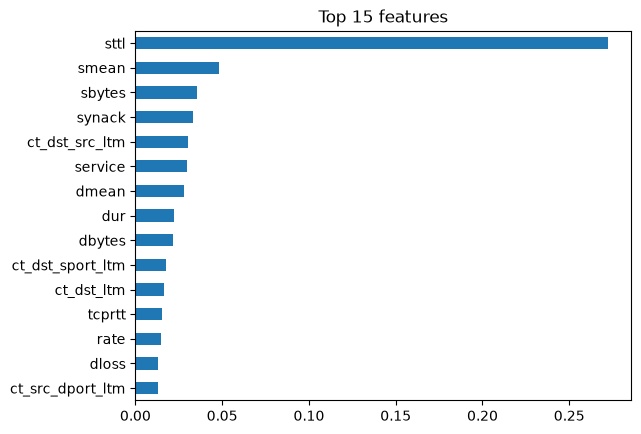

In [9]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

r = permutation_importance(final, X_test.sample(5000, random_state=0),
                           y_test.loc[X_test.sample(5000, random_state=0).index],
                           n_repeats=3, random_state=0, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X.columns).nlargest(15)
imp.sort_values().plot.barh(); plt.title("Top 15 features"); plt.show()

In [10]:
pred = (p_test >= THRESHOLD)
fpr = ((pred == 1) & (y_test == 0)).sum() / (y_test == 0).sum()
tpr = ((pred == 1) & (y_test == 1)).sum() / (y_test == 1).sum()
for base in [0.01, 0.02, 0.05]:
    tp, fp = base * tpr, (1 - base) * fpr
    print(f"{base:.0%} attacks -> precision {tp / (tp + fp):.3f}")

1% attacks -> precision 0.037
2% attacks -> precision 0.072
5% attacks -> precision 0.166


In [11]:
joblib.dump({"pipeline": final, "threshold": THRESHOLD, "features": list(X.columns)},
            "../models/classifier.joblib")

['../models/classifier.joblib']